# Agentes Basados en el Conocimiento - Predador presa

El problema predador–presa es un modelo clásico para estudiar la interacción entre dos poblaciones: una de presas, que buscan sobrevivir y reproducirse, y otra de predadores, que intentan capturarlas para alimentarse. Este tipo de modelos permite analizar cómo comportamientos simples a nivel individual generan dinámicas colectivas complejas, como ciclos poblacionales, extinciones o equilibrios dinámicos.

En esta simulación se adopta un enfoque de Inteligencia Artificial basada en agentes, donde cada predador y cada presa es un agente autónomo que percibe su entorno local (vecindario Moore) y toma decisiones: las presas detectan predadores y escapan, o forrajean hacia el pasto; los predadores detectan presas, las persiguen y pueden fallar la captura. Las presas se alimentan de una capa de **pasto renovable** que se regenera celda por celda. A partir de estas reglas locales emergen los ciclos poblacionales clásicos de Lotka–Volterra.

# Simulación

In [56]:
%pip install mesa --quiet

/Users/oh/World/External/Study/UR/IAPS-I/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


Código preparado para la versión 3.5.1 de mesa

In [57]:
import mesa

print(mesa.__version__)

3.5.1


Librerías

In [58]:
import random

import matplotlib.pyplot as plt
import mesa
from mesa import Agent, Model
import numpy as np

## El modelo

**Presa** — en cada paso:
1. Gasta energía (metabolismo).
2. *Percibe*: si hay un predador en su vecindario (incluida su celda), con prob. `escape_prob` **escapa** a la casilla vecina más lejana de la amenaza más cercana (distancia toroidal).
3. Sin amenaza, **forrajea**: prefiere casillas con pasto crecido.
4. Come el pasto de su celda si está crecido (+`grass_energy`, el pasto tarda `grass_regrow` pasos en volver a crecer).
5. Se reproduce con prob. `prey_reproduce` si tiene energía suficiente: **cuesta la mitad de su energía**.
6. Muere si su energía llega a 0.

**Predador** — en cada paso:
1. Gasta energía (metabolismo).
2. *Caza*: si detecta una presa en su vecindario (prob. `hunt_prob`) se mueve hacia la más cercana.
3. Si comparte celda con una presa, la captura con prob. `catch_prob` (**la caza puede fallar**) y gana `pred_gain_food` de energía (con tope `pred_max_energy`).
4. Se reproduce con prob. `pred_reproduce` si tiene energía suficiente (cuesta la mitad).
5. Muere si su energía llega a 0.

In [59]:
class CustomScheduler:
    """Programador con activación en orden aleatorio.

    El orden aleatorio evita ventajas sistemáticas por turno
    (ejercicios: ¿qué pasa si se quita?).
    """

    def __init__(self, model):
        self.model = model
        self.agents = []

    def add(self, agent):
        self.agents.append(agent)

    def remove(self, agent):
        if agent in self.agents:
            self.agents.remove(agent)

    def shuffle_do(self, method_name):
        agent_list = list(self.agents)
        random.shuffle(agent_list)
        for agent in agent_list:
            if agent in self.agents:  # el agente aún existe (no fue comido ni murió antes)
                getattr(agent, method_name)()

    def step(self):
        self.shuffle_do("step")


class Prey(Agent):
    """Presa: percibe predadores, escapa, forrajea pasto y se reproduce."""

    def __init__(self, model, energy=None):
        super().__init__(model)
        self.energy = model.initial_prey_energy if energy is None else energy

    def step(self):
        m = self.model
        self.energy -= m.prey_metabolism

        possible_steps = m.grid.get_neighborhood(
            self.pos, moore=True, include_center=False
        )

        # Percepción: predadores en el vecindario Moore (incluida mi propia celda)
        threats = [
            a.pos
            for pos in m.grid.get_neighborhood(self.pos, moore=True, include_center=True)
            for a in m.grid.get_cell_list_contents([pos])
            if isinstance(a, Predator)
        ]
        if threats and random.random() < m.escape_prob:
            # Escape: casilla vecina más lejana de la amenaza más cercana
            new_position = max(
                possible_steps, key=lambda p: min(m.torus_dist(p, t) for t in threats)
            )
        else:
            # Forrajeo: preferir casillas con pasto crecido (0 = crecido)
            grown = [p for p in possible_steps if m.grass[p[1], p[0]] == 0]
            new_position = random.choice(grown) if grown else random.choice(possible_steps)

        m.grid.move_agent(self, new_position)

        # Alimentación: comer el pasto de la celda si ya creció
        x, y = self.pos
        if m.grass[y, x] == 0:
            self.energy += m.grass_energy
            m.grass[y, x] = m.grass_regrow

        # Reproducción: probabilística, transfiere la mitad de la energía
        if self.energy > m.prey_reproduce_min and random.random() < m.prey_reproduce:
            self.energy /= 2
            child = Prey(m, energy=self.energy)
            m.grid.place_agent(child, self.pos)
            m.schedule.add(child)
            if m.verbose:
                print(f"Presa {self.unique_id} se reprodujo -> nace {child.unique_id}")

        # Muerte por inanición
        if self.energy <= 0:
            if m.verbose:
                print(f"Presa {self.unique_id} murió de hambre")
            m.remove_agent(self)


class Predator(Agent):
    """Predador: detecta presas, las persigue y puede fallar la captura."""

    def __init__(self, model, energy=None):
        super().__init__(model)
        self.energy = model.initial_pred_energy if energy is None else energy

    def step(self):
        m = self.model
        self.energy -= m.pred_metabolism

        possible_steps = m.grid.get_neighborhood(
            self.pos, moore=True, include_center=False
        )

        # Percepción: presas en el vecindario Moore (incluida mi propia celda)
        prey_positions = [
            a.pos
            for pos in m.grid.get_neighborhood(self.pos, moore=True, include_center=True)
            for a in m.grid.get_cell_list_contents([pos])
            if isinstance(a, Prey)
        ]
        if prey_positions and random.random() < m.hunt_prob:
            # Caza: moverse (o quedarse) a la casilla más cercana a la presa más próxima
            new_position = min(
                list(possible_steps) + [self.pos],
                key=lambda p: min(m.torus_dist(p, q) for q in prey_positions),
            )
        else:
            new_position = random.choice(possible_steps)

        m.grid.move_agent(self, new_position)

        # Captura: si comparto celda con una presa, cazar con prob. catch_prob
        for agent in m.grid.get_cell_list_contents([self.pos]):
            if isinstance(agent, Prey) and random.random() < m.catch_prob:
                self.energy = min(self.energy + m.pred_gain_food, m.pred_max_energy)
                if m.verbose:
                    print(f"Predador {self.unique_id} cazó a la presa {agent.unique_id}")
                m.remove_agent(agent)
                break

        # Reproducción: probabilística, transfiere la mitad de la energía
        if self.energy > m.pred_reproduce_min and random.random() < m.pred_reproduce:
            self.energy /= 2
            child = Predator(m, energy=self.energy)
            m.grid.place_agent(child, self.pos)
            m.schedule.add(child)
            if m.verbose:
                print(f"Predador {self.unique_id} se reprodujo -> nace {child.unique_id}")

        # Muerte por inanición
        if self.energy <= 0:
            if m.verbose:
                print(f"Predador {self.unique_id} murió de hambre")
            m.remove_agent(self)


class PredatorPreyModel(Model):
    def __init__(
        self,
        n_prey=100,
        n_predators=10,
        width=20,
        height=20,
        # Energía
        initial_prey_energy=10,
        initial_pred_energy=20,
        prey_metabolism=1,
        pred_metabolism=1,
        grass_energy=5,      # energía que gana una presa al comer pasto
        pred_gain_food=12,   # energía que gana un predador al cazar
        pred_max_energy=30,  # tope: un predador no acumula energía infinita
        # Pasto
        grass_regrow=12,          # pasos que tarda el pasto en volver a crecer
        grass_initial_prob=0.5,   # fracción de celdas que inician con pasto crecido
        # Reproducción
        prey_reproduce=0.12,
        prey_reproduce_min=6,
        pred_reproduce=0.025,
        pred_reproduce_min=14,
        # Percepción
        escape_prob=0.9,  # prob. de que la presa huya al ver un predador
        hunt_prob=0.5,    # prob. de que el predador detecte una presa
        catch_prob=0.3,   # prob. de éxito en la captura
        verbose=False,
    ):
        super().__init__()
        self.grid = mesa.space.MultiGrid(width, height, torus=True)
        self.schedule = CustomScheduler(self)
        self.verbose = verbose

        self.initial_prey_energy = initial_prey_energy
        self.initial_pred_energy = initial_pred_energy
        self.prey_metabolism = prey_metabolism
        self.pred_metabolism = pred_metabolism
        self.grass_energy = grass_energy
        self.pred_gain_food = pred_gain_food
        self.pred_max_energy = pred_max_energy
        self.grass_regrow = grass_regrow
        self.prey_reproduce = prey_reproduce
        self.prey_reproduce_min = prey_reproduce_min
        self.pred_reproduce = pred_reproduce
        self.pred_reproduce_min = pred_reproduce_min
        self.escape_prob = escape_prob
        self.hunt_prob = hunt_prob
        self.catch_prob = catch_prob

        # Capa de pasto: 0 = crecido (listo para comer), >0 = pasos para volver a crecer
        self.grass = np.where(
            np.random.rand(height, width) < grass_initial_prob, 0, grass_regrow
        )

        # Presas
        for _ in range(n_prey):
            prey = Prey(self)
            self.grid.place_agent(prey, self.random_pos())
            self.schedule.add(prey)

        # Predadores
        for _ in range(n_predators):
            predator = Predator(self)
            self.grid.place_agent(predator, self.random_pos())
            self.schedule.add(predator)

        self.datacollector = mesa.datacollection.DataCollector(
            model_reporters={
                "Prey": lambda m: sum(isinstance(a, Prey) for a in m.schedule.agents),
                "Predators": lambda m: sum(isinstance(a, Predator) for a in m.schedule.agents),
                "Grass": lambda m: int((m.grass == 0).sum()),
            }
        )

    def random_pos(self):
        return (
            random.randint(0, self.grid.width - 1),
            random.randint(0, self.grid.height - 1),
        )

    def torus_dist(self, a, b):
        """Distancia euclídea al cuadrado en el toro (la grilla es toroidal)."""
        dx = abs(a[0] - b[0])
        dy = abs(a[1] - b[1])
        dx = min(dx, self.grid.width - dx)
        dy = min(dy, self.grid.height - dy)
        return dx * dx + dy * dy

    def remove_agent(self, agent):
        self.grid.remove_agent(agent)
        self.schedule.remove(agent)

    def step(self):
        self.datacollector.collect(self)
        self.schedule.step()
        # Regeneración del pasto
        regrowing = self.grass > 0
        self.grass[regrowing] -= 1

## Visualización

In [60]:
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

GRASS_CMAP = ListedColormap(["#1f4030", "#7cc26a"])  # [creciendo, crecido]


def draw_frame(frame, ax):
    """Dibuja un frame: pasto (verde), presas (blanco) y predadores (rojo)."""
    grown = (frame["grass"] == 0).astype(float)
    h, w = grown.shape
    ax.imshow(grown, cmap=GRASS_CMAP, vmin=0, vmax=1,
              interpolation="nearest", extent=(0, w, h, 0))
    if len(frame["prey"]):
        ax.scatter(frame["prey"][:, 0] + 0.5, frame["prey"][:, 1] + 0.5,
                   c="white", s=55, edgecolors="black", linewidths=0.4, zorder=2)
    if len(frame["pred"]):
        ax.scatter(frame["pred"][:, 0] + 0.5, frame["pred"][:, 1] + 0.5,
                   c="#e03131", marker="^", s=110, edgecolors="black",
                   linewidths=0.4, zorder=3)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(
        f"Paso {frame['step']}  ·  presas: {len(frame['prey'])}  ·  "
        f"predadores: {len(frame['pred'])}"
    )

In [61]:
# Parámetros (semilla fija para que el demo sea reproducible)
random.seed(42)
np.random.seed(42)

model_params = {
    "n_prey": 100,
    "n_predators": 20,
    "width": 20,
    "height": 20,
}

model = PredatorPreyModel(**model_params)

In [62]:
# Corro el modelo guardando un frame por paso
steps = 300
frames = []


def capture_frame(m, step):
    frames.append({
        "step": step,
        "grass": m.grass.copy(),
        "prey": np.array([a.pos for a in m.schedule.agents if isinstance(a, Prey)]),
        "pred": np.array([a.pos for a in m.schedule.agents if isinstance(a, Predator)]),
    })


capture_frame(model, 0)
for i in range(1, steps + 1):
    model.step()
    capture_frame(model, i)

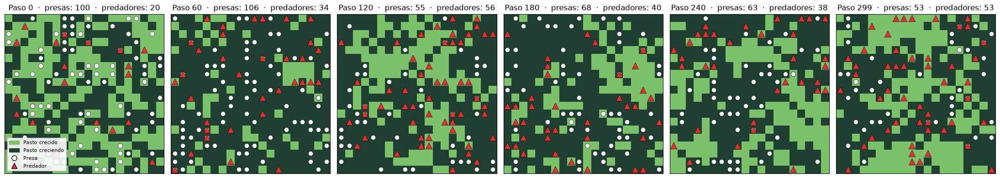

In [63]:
# Instantáneas de la evolución (una fila)
snapshot_steps = [0, 60, 120, 180, 240, 299]    # [60**i-1 for i in range(6)]

fig, axes = plt.subplots(1, len(snapshot_steps), figsize=(22, 4.4))
for ax, s in zip(axes, snapshot_steps):
    draw_frame(frames[s], ax)

axes[0].legend(
    handles=[
        Patch(color="#7cc26a", label="Pasto crecido"),
        Patch(color="#1f4030", label="Pasto creciendo"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
               markeredgecolor="black", markersize=8, label="Presa"),
        Line2D([0], [0], marker="^", color="none", markerfacecolor="#e03131",
               markeredgecolor="black", markersize=9, label="Predador"),
    ],
    loc="lower left", fontsize=8, framealpha=0.9,
)
plt.tight_layout()
plt.show()

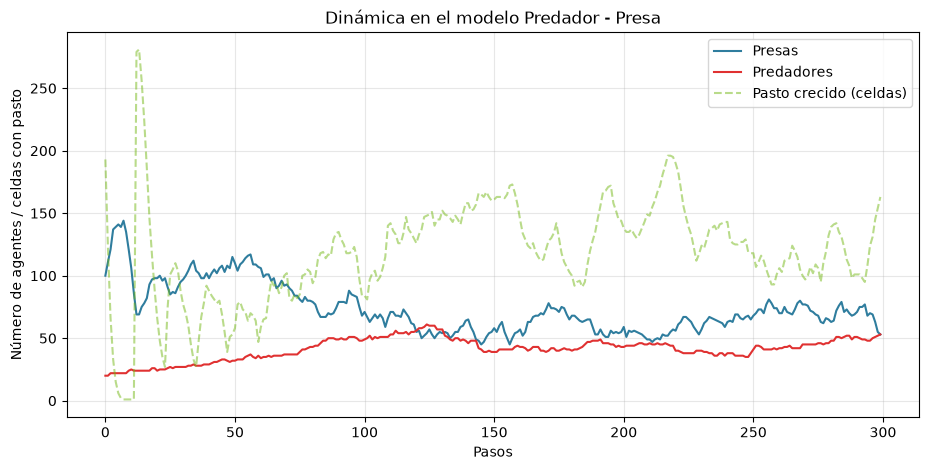

In [64]:
# Curvas de población
results = model.datacollector.get_model_vars_dataframe()

plt.figure(figsize=(11, 5))
plt.plot(results["Prey"], label="Presas", color="#2f7d9e")
plt.plot(results["Predators"], label="Predadores", color="#e03131")
plt.plot(results["Grass"], label="Pasto crecido (celdas)", color="#74b816",
         alpha=0.5, ls="--")
plt.xlabel("Pasos")
plt.ylabel("Número de agentes / celdas con pasto")
plt.title("Dinámica en el modelo Predador - Presa")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## ¿Qué hace estable el sistema?

**Por qué se moría todo antes:**

- La comida era **una sola celda que se teletransportaba** cada paso: una presa que camina al azar en una grilla 20×20 casi nunca la encuentra, así que todas morían de hambre en ~10 pasos (y los predadores justo detrás).
- El "escape" restaba 5 de energía pero **no alejaba a la presa**: quitaba de la lista de movimientos una posición que ya estaba excluida de antemano. Solo aceleraba la muerte.

**Los cuatro pilares de la estabilidad** (los mismos que producen las oscilaciones de la gráfica):

1. **Recurso renovable y distribuido.** Cada celda tiene pasto que vuelve a crecer en 12 pasos. Eso fija una *capacidad de carga*: solo hay ~400/12 ≈ 33 celdas con pasto nuevo por paso (~165 energía/paso), así que las presas no crecen sin límite… pero tampoco quedan nunca "sin planeta".
2. **Depredación imperfecta (acoplamiento débil).** La caza puede fallar en dos puntos (el predador no siempre detecta con `hunt_prob`, y la captura falla con 1−`catch_prob`) y la presa puede **escapar de verdad** (percibe su vecindario y maximiza la distancia). Con eficiencia de caza baja, un boom de predadores no puede comerse todas las presas de golpe.
3. **Respuesta con retardo.** Los predadores se reproducen lento (2.5% por paso, exigiendo energía > 14) y reproducirse cuesta la mitad de la energía. Su población *sigue* a la de las presas con retraso: es exactamente el mecanismo de Lotka–Volterra que genera el ciclo (presas ↑ → predadores ↑ → presas ↓ → predadores ↓) en lugar de un equilibrio instantáneo o un colapso.
4. **Amortiguadores.** El tope de energía del predador (`pred_max_energy`) impide acumular energía en la abundancia, recortando los booms posteriores; y la muerte por inanición hace que cuando las presas escasean la presión depredadora caiga rápido, dejando que las presas reboten.

En conjunto: **acoplamiento débil + retardos generan la oscilación; capacidad de carga + topes + inanición la mantienen acotada** (sin extinciones).

In [65]:
# Animación interactiva: panel con play, pausa y deslizador
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

plt.rcParams["animation.embed_limit"] = 60  # MB permitidos de animación embebida

fig, ax = plt.subplots(figsize=(6.5, 6.5))


def animate(i):
    ax.clear()
    draw_frame(frames[i], ax)
    ax.legend(
        handles=[
            Patch(color="#7cc26a", label="Pasto crecido"),
            Patch(color="#1f4030", label="Pasto creciendo"),
            Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
                   markeredgecolor="black", markersize=8, label="Presa"),
            Line2D([0], [0], marker="^", color="none", markerfacecolor="#e03131",
                   markeredgecolor="black", markersize=9, label="Predador"),
        ],
        loc="lower left", fontsize=8, framealpha=0.9,
    )


anim = FuncAnimation(fig, animate, frames=len(frames), interval=100)
plt.close(fig)  # la figura vive dentro del panel interactivo
HTML(anim.to_jshtml())

## Ejercicios:

* Quitar la aleatoriedad en la activación de los agentes. ¿cómo cambia la simulación? ¿aparecen patrones artificiales?
* ¿cómo puedo hacer que las presas se muevan más rápido?
* Variar parámetros de probabilidad de reproducción.
* Haga que las presas busquen en el vecindario. Ya no se mueven aleatoriamente.
* Haga que las presas detecten predadores y se alejen.

### Respuestas

**1. Quitar la aleatoriedad en la activación.** Con orden fijo aparece una ventaja sistemática por turno: si todas las presas actúan antes que los predadores, siempre escapan primero y la eficiencia de caza se desploma (los predadores tienden a extinguirse); al revés, los predadores siempre cazan con la presa quietas. Además emergen patrones artificiales de sincronización ("olas" de movimiento coordinado) que no existen en un orden aleatorio. Por eso `CustomScheduler.shuffle_do` baraja el orden en cada paso.

**2. Presas más rápidas.** Darles una "velocidad" `k`: repetir su movimiento `k` veces por paso (o ampliar su vecindario a radio `k`). Si solo las presas aceleran, la captura se vuelve rarísima y los predadores desaparecen (la única forma de que sobrevivan es acelerar ellos también o subir `catch_prob`). También conviene cobrar energía por cada movimiento extra, si no, el pasto sufre sobre-pastoreo por el mayor radio de forrajeo.

**3. Variar la probabilidad de reproducción.** Es el parámetro más sensible del sistema: subir la de las presas amplía la amplitud de los ciclos (más boom-bust y riesgo de agotar el pasto y morir de hambre en masa); subir la de los predadores produce el crash clásico (se comen todo y luego mueren de inanición); bajarlas demasiado arriesga extinción estocástica por deriva. La coexistencia requiere que las presas se recuperen notablemente más rápido de lo que los predadores responden (por eso aquí 0.12 vs 0.025).

**4. Presas que buscan en el vecindario.** Ya está implementado en la base: sin amenazas, la presa prefiere moverse a casillas con pasto crecido (forrajeo dirigido). El efecto visible en la animación son frentes de sobre-pastoreo (el pasto se agota alrededor de los grupos) y agregación de presas sobre parches, lo que a su vez las hace más fáciles de encontrar para los predadores (predación densodependiente).

**5. Presas que detectan predadores y se alejan.** También está implementado: la presa percibe su vecindario Moore (incluida su propia celda) y con prob. `escape_prob = 0.9` se mueve a la casilla que maximiza la distancia toroidal a la amenaza más cercana. Su efecto sobre la estabilidad es bajar la eficiencia de caza: el equilibrio de predadores queda más bajo y los ciclos se suavizan. Si se pone a 1.0 y las presas siempre escapan, la captura solo es posible cuando el predador actúa primero y acierta.